In [26]:
import pickle
from pathlib import Path

import numpy as np
import jax
import jax.numpy as jnp
import jax.scipy as jsp
import scipy
import matplotlib.pyplot as plt
import operator
from jax import config
from functools import partial
from matplotlib.lines import Line2D
config.update("jax_enable_x64", True)

import os

import polars as pl
import statistics

from matplotlib.colors import CenteredNorm
import scipy.stats as scis
# from scipy.stats import norm
from cmfa.functions import ordered_ilr_func, closure


In [27]:
RESULTS_DIR = Path("..") / "data" / "results" / "toy_example"
PLOT_DIR = Path("..") / "figures"

In [28]:
true_flux = np.load(RESULTS_DIR / "true_flux.npy")
true_id = np.load(RESULTS_DIR / "true_composition.npy")
print(f"True flux: {true_flux}")
print(f"True isotopologue distribution: {true_id}")


True flux: [100. 110.  50.  20.  20.  80.]
True isotopologue distribution: [6.34920635e-05 8.00761905e-01 1.98285714e-01 8.88888889e-04]


We start with analysis of the reference flux set from Antoniwitch 

In [29]:
intensity_msts = jnp.load(RESULTS_DIR / "intensity_measurements_reference.npy")
simulated_id = jnp.load(RESULTS_DIR / "id_simulated_reference.npy")

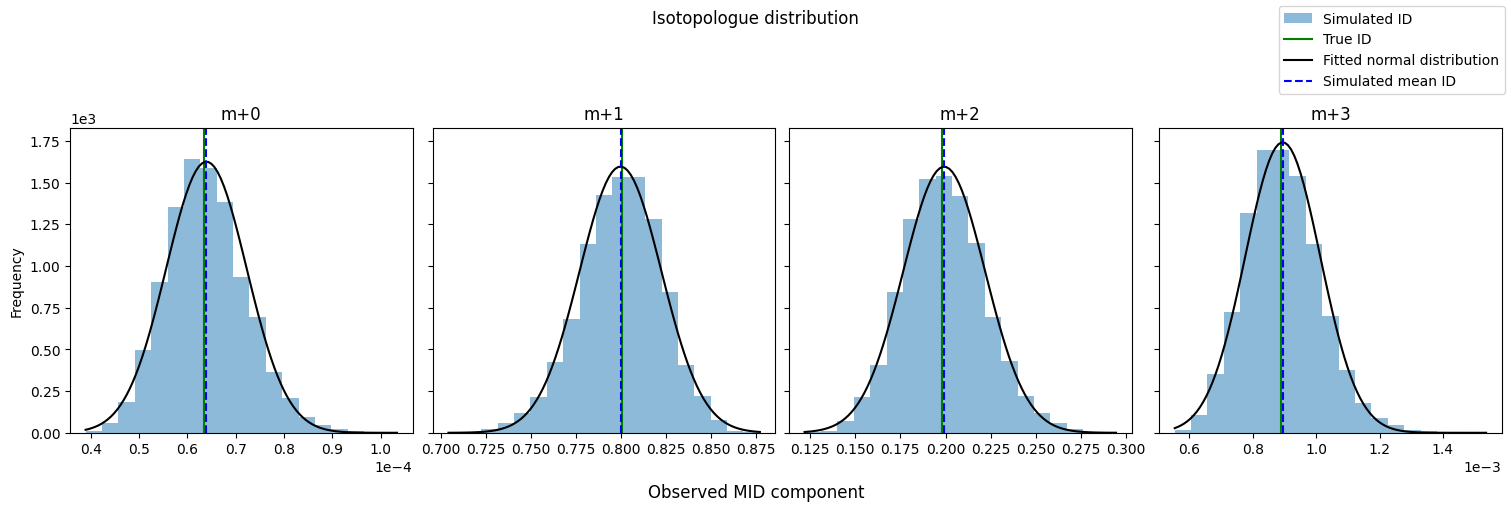

In [30]:
f, axes = plt.subplots(1, 4, figsize=[15, 5], sharey=True, layout='constrained')

for (i, ax) in enumerate(axes):
    simulated_id_i = simulated_id[:,i].flatten()
    xmin = np.min(simulated_id_i)
    xmax = np.max(simulated_id_i)
    bins = np.linspace(xmin, xmax, 20)
    bin_width = bins[1] - bins[0]
    h_trad = ax.hist(
        simulated_id_i, 
        bins=bins,
        alpha=0.5,
        label=f"Simulated ID",
    )
    ax.set(title=f"m+{i}")
    ax.axvline(true_id[i], label="True ID", color="green")
    mu, std = scis.norm.fit(simulated_id_i)
    x = np.linspace(xmin, xmax, 100)
    p = scis.norm.pdf(x, mu, std)
    scaled_p = p * len(simulated_id_i) * bin_width
    ax.plot(x, scaled_p, "k", label="Fitted normal distribution")
    ax.axvline(mu, label="Simulated mean ID", color="blue", linestyle="--")
    ax.ticklabel_format(scilimits=(-2,3))
    # ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");
h,l = ax.get_legend_handles_labels()
f.supxlabel("Observed MID component")
f.legend(labels=l, loc="outside upper right")
f.suptitle("Isotopologue distribution");
f.savefig(PLOT_DIR / "simulated_id_toy.png", bbox_inches="tight", dpi=200)


simulated_id.std(axis=0)

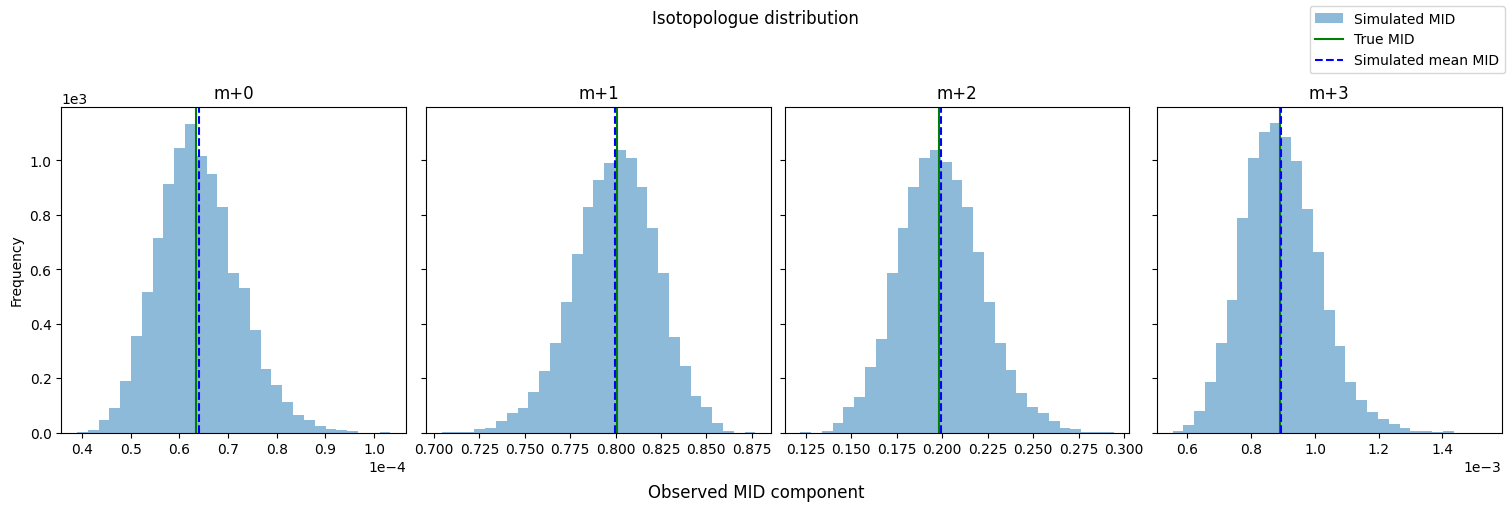

In [31]:
f, axes = plt.subplots(1, 4, figsize=[15, 5], sharey=True, layout='constrained')

for (i, ax) in enumerate(axes):
    simulated_id_i = simulated_id[:,i].flatten()
    xmin = np.min(simulated_id_i)
    xmax = np.max(simulated_id_i)
    bins = np.linspace(xmin, xmax, 30)
    bin_width = bins[1] - bins[0]
    h_trad = ax.hist(
        simulated_id_i, 
        bins=bins,
        alpha=0.5,
        label=f"Simulated MID",
    )
    ax.set(title=f"m+{i}")
    ax.axvline(true_id[i], label="True MID", color="green")
    mu, std = scis.norm.fit(simulated_id_i)
    x = np.linspace(xmin, xmax, 100)
    p = scis.norm.pdf(x, mu, std)
    scaled_p = p * len(simulated_id_i) * bin_width
    # ax.plot(x, scaled_p, "k", label="Fitted normal distribution")
    ax.axvline(mu, label="Simulated mean MID", color="blue", linestyle="--")
    ax.ticklabel_format(scilimits=(-2,3))
    # ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");
h,l = ax.get_legend_handles_labels()
f.supxlabel("Observed MID component")
f.legend(labels=l, loc="outside upper right")
f.suptitle("Isotopologue distribution");
f.savefig(PLOT_DIR / "simulated_mid_toy.png", bbox_inches="tight", dpi=200)


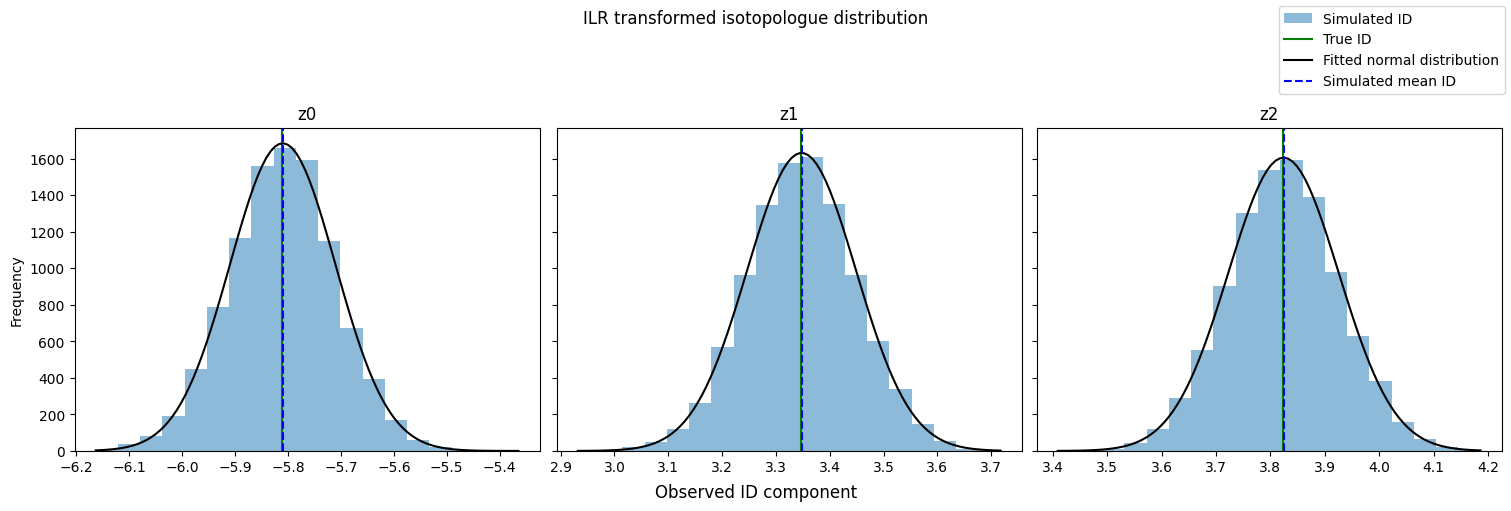

In [32]:
ilr_id_msts_true = ordered_ilr_func(simulated_id)
true_ilr_mid = ordered_ilr_func(true_id)
f, axes = plt.subplots(1, 3, figsize=[15, 5], sharey=True, layout="constrained")

for (i, ax) in enumerate(axes):
    ilr_id_i = ilr_id_msts_true[:,i].flatten()
    xmin = np.min(ilr_id_i)
    xmax = np.max(ilr_id_i)
    bins = np.linspace(xmin, xmax, 20)
    bin_width = bins[1] - bins[0]
    h_trad = ax.hist(
        ilr_id_i, 
        bins=bins,
        alpha=0.5,
        label=f"Simulated ID" 
    )
    ax.set(title=f"z{i}")
    ax.axvline(true_ilr_mid[i], label="True ID", color="green")
    mu, std = scis.norm.fit(ilr_id_i)
    x = np.linspace(xmin, xmax, 100)
    p = scis.norm.pdf(x, mu, std)
    scaled_p = p * len(ilr_id_i) * bin_width
    ax.plot(x, scaled_p, "k", label="Fitted normal distribution")
    ax.axvline(mu, label="Simulated mean ID", color="blue", linestyle="--")
    # ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");
h,l = ax.get_legend_handles_labels()
f.supxlabel("Observed ID component")
f.legend(labels=l, loc="outside upper right")
f.suptitle("ILR transformed isotopologue distribution");
f.savefig(PLOT_DIR / "simulated_ilr_toy.png", bbox_inches="tight", dpi=200)

In [33]:
with open(RESULTS_DIR / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_ref = pickle.load(f)
estimated_fluxes_ref["trad"].shape

(10000, 6)

In [34]:
estimated_fluxes_ref["trad"][:,:].mean(axis=0)

Array([112.02061949,  20.03717669,  79.96282331, 100.        ,
        52.09497286,  20.03717669], dtype=float64)

In [35]:
estimated_fluxes_ref["trad"][:,0].max()

Array(265.51711633, dtype=float64)

In [36]:
# Column order in the estimated_fluxes_ref array
col_order = ["v2", "v4", "v6", "v1", "v3", "v5"]
col_index = {name: i for i, name in enumerate(col_order)}

# true_flux array is ordered v1..v6
true_flux_map = {f"v{i+1}": float(true_flux[i]) for i in range(6)}

flux_keys = ["v2", "v3", "v4", "v5", "v6"]  # v1 excluded

rows = []
for model in ("trad", "ilr"):
    arr = np.array(estimated_fluxes_ref[model])  # shape (N, 6)
    for flux_name in flux_keys:
        col = arr[:, col_index[flux_name]]
        rows.append({
            "model": model,
            "flux": flux_name,
            "true_value": true_flux_map[flux_name],
            "median": float(np.median(col)),
            "min": float(np.min(col)),
            "max": float(np.max(col)),
            "q25": float(np.quantile(col, 0.25)),
            "q75": float(np.quantile(col, 0.75)),
        })

summary_df_toy = pl.DataFrame(rows)
summary_df_toy.write_csv(RESULTS_DIR / "estimated_fluxes_reference_summary.csv")
print(summary_df_toy.to_pandas().to_string(index=False))

model flux  true_value     median       min        max        q25        q75
 trad   v2       110.0 109.844672 72.563415 265.517116 100.731467 120.875892
 trad   v3        50.0  49.986073 24.443107 193.630232  42.847721  58.922381
 trad   v4        20.0  20.015206 14.012285  26.861354  18.888643  21.167835
 trad   v5        20.0  20.015206 14.012285  26.861354  18.888643  21.167835
 trad   v6        80.0  79.984794 73.138646  85.987715  78.832165  81.111357
  ilr   v2       110.0 110.068021 73.398209 267.962011 101.183480 120.054613
  ilr   v3        50.0  50.018433 25.076801 196.058404  43.518100  57.895028
  ilr   v4        20.0  20.013511 14.048196  26.758693  18.894809  21.153746
  ilr   v5        20.0  20.013511 14.048196  26.758693  18.894809  21.153746
  ilr   v6        80.0  79.986489 73.241307  85.951804  78.846254  81.105191


In [37]:
col_rename = {
    "flux": "Flux",
    "true_value": "True value",
    "median": "Median",
    "min": "Min",
    "max": "Max",
    "q25": "Q25",
    "q75": "Q75",
}

for model, label in (("trad", "Traditional I-MFA"), ("ilr", "Compositional I-MFA")):
    df = (
        summary_df_toy.filter(pl.col("model") == model)
        .drop("model")
        .rename(col_rename)
        .to_pandas()
    )
    latex = df.to_latex(
        index=False,
        float_format="%.3f",
        caption=f"Estimated fluxes — {label}",
        label=f"tab:toy_fluxes_{model}",
    )
    print(f"% --- {label} ---")
    print(latex)

% --- Traditional I-MFA ---
\begin{table}
\caption{Estimated fluxes — Traditional I-MFA}
\label{tab:toy_fluxes_trad}
\begin{tabular}{lrrrrrr}
\toprule
Flux & True value & Median & Min & Max & Q25 & Q75 \\
\midrule
v2 & 110.000 & 109.845 & 72.563 & 265.517 & 100.731 & 120.876 \\
v3 & 50.000 & 49.986 & 24.443 & 193.630 & 42.848 & 58.922 \\
v4 & 20.000 & 20.015 & 14.012 & 26.861 & 18.889 & 21.168 \\
v5 & 20.000 & 20.015 & 14.012 & 26.861 & 18.889 & 21.168 \\
v6 & 80.000 & 79.985 & 73.139 & 85.988 & 78.832 & 81.111 \\
\bottomrule
\end{tabular}
\end{table}

% --- Compositional I-MFA ---
\begin{table}
\caption{Estimated fluxes — Compositional I-MFA}
\label{tab:toy_fluxes_ilr}
\begin{tabular}{lrrrrrr}
\toprule
Flux & True value & Median & Min & Max & Q25 & Q75 \\
\midrule
v2 & 110.000 & 110.068 & 73.398 & 267.962 & 101.183 & 120.055 \\
v3 & 50.000 & 50.018 & 25.077 & 196.058 & 43.518 & 57.895 \\
v4 & 20.000 & 20.014 & 14.048 & 26.759 & 18.895 & 21.154 \\
v5 & 20.000 & 20.014 & 14.048 & 26.759

In [9]:
with open(RESULTS_DIR / "estimated_ids_reference.pkl", "rb") as f:
    estimated_ids_ref = pickle.load(f)
estimated_ids_ref["trad"].shape

(10000, 4)

In [10]:
resid_trad = (true_flux[None, [2, 4]] - estimated_fluxes_ref["trad"][:, [4,5]])
resid_clr = (true_flux[None, [2, 4]] - estimated_fluxes_ref["clr"][:, [4,5]])
resid_ilr = (true_flux[None, [2, 4]] - estimated_fluxes_ref["ilr"][:, [4,5]])

mse_trad = (resid_trad ** 2).mean(axis=(0))
mse_clr = (resid_clr ** 2).mean(axis=(0))
mse_ilr = (resid_ilr ** 2).mean(axis=(0))

mse_trad, mse_clr, mse_ilr

(Array([181.12988194,   2.87196816], dtype=float64),
 Array([142.17026371,   2.84658239], dtype=float64),
 Array([142.17064515,   2.84664011], dtype=float64))

In [11]:
id_resid_trad = (estimated_ids_ref["trad"] - true_id)
id_resid_clr = (estimated_ids_ref["clr"] - true_id)
id_resid_ilr = (estimated_ids_ref["ilr"] - true_id)

id_mse_trad = (id_resid_trad ** 2).mean(axis=(0))
id_mse_clr = (id_resid_clr ** 2).mean(axis=(0))
id_mse_ilr = (id_resid_ilr ** 2).mean(axis=(0))

id_mse_trad, id_mse_clr, id_mse_ilr

(Array([1.21515366e-10, 5.17115542e-04, 5.15180950e-04, 1.16571362e-08],      dtype=float64),
 Array([6.11304725e-11, 4.98401325e-04, 4.95870011e-04, 7.64706917e-09],      dtype=float64),
 Array([6.11249932e-11, 4.98412060e-04, 4.95880656e-04, 7.64672549e-09],      dtype=float64))

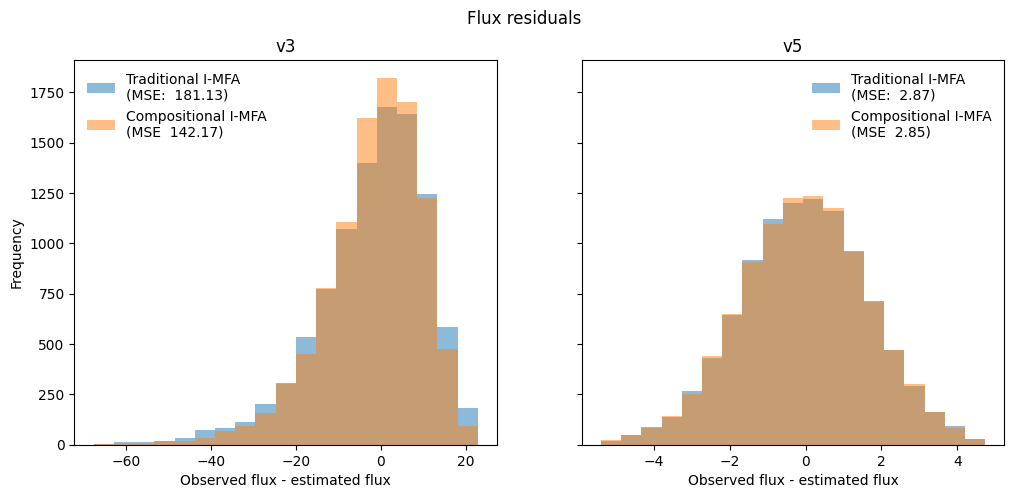

In [12]:
f, axes = plt.subplots(1, 2, figsize=[12, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_trad_i = resid_trad[:, i].flatten()
    resid_comp_i = resid_ilr[:, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 20)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {mse_trad[i]: .2f})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE {mse_ilr[i]: .2f})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{3+2*i}", xlabel="Observed flux - estimated flux")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");

f.suptitle("Flux residuals");
f.savefig(PLOT_DIR / "flux_residuals_toy_true.png", bbox_inches="tight", dpi=200)

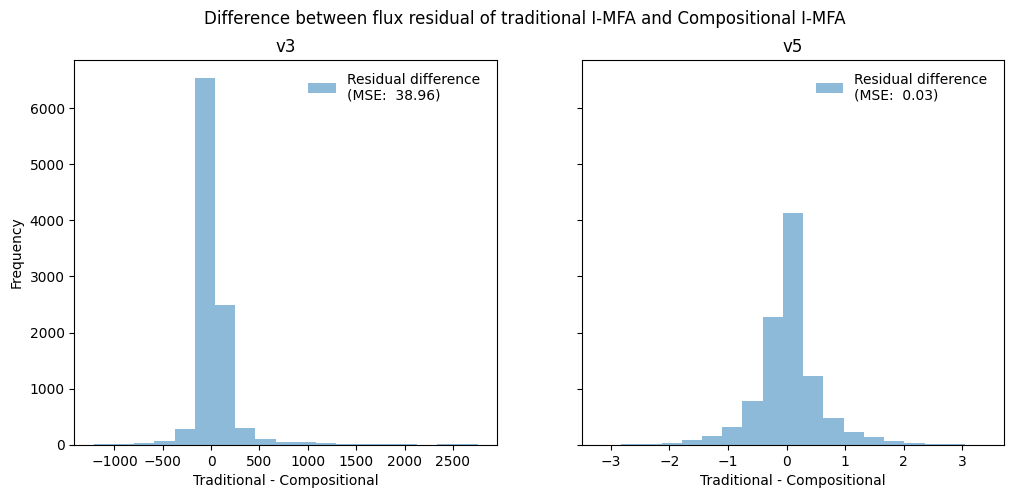

In [13]:
resid_diff = resid_trad**2-resid_ilr**2
mse_diff = (resid_diff).mean(axis=(0))

f, axes = plt.subplots(1, 2, figsize=[12, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_diff_i = resid_diff[:, i].flatten()
    xmin = np.quantile(resid_diff_i, 0.001)
    xmax = np.quantile(resid_diff_i, 0.999)
    bins = np.linspace(xmin, xmax, 20)
    h_trad = ax.hist(
        resid_diff_i, 
        bins=bins,
        alpha=0.5,
        label=f"Residual difference \n(MSE: {mse_diff[i]: .2f})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{3+2*i}", xlabel="Traditional - Compositional")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");

f.suptitle("Difference between flux residual of traditional I-MFA and Compositional I-MFA");
# f.savefig(PLOT_DIR / "flux_residuals_toy_true.png", bbox_inches="tight", dpi=200)

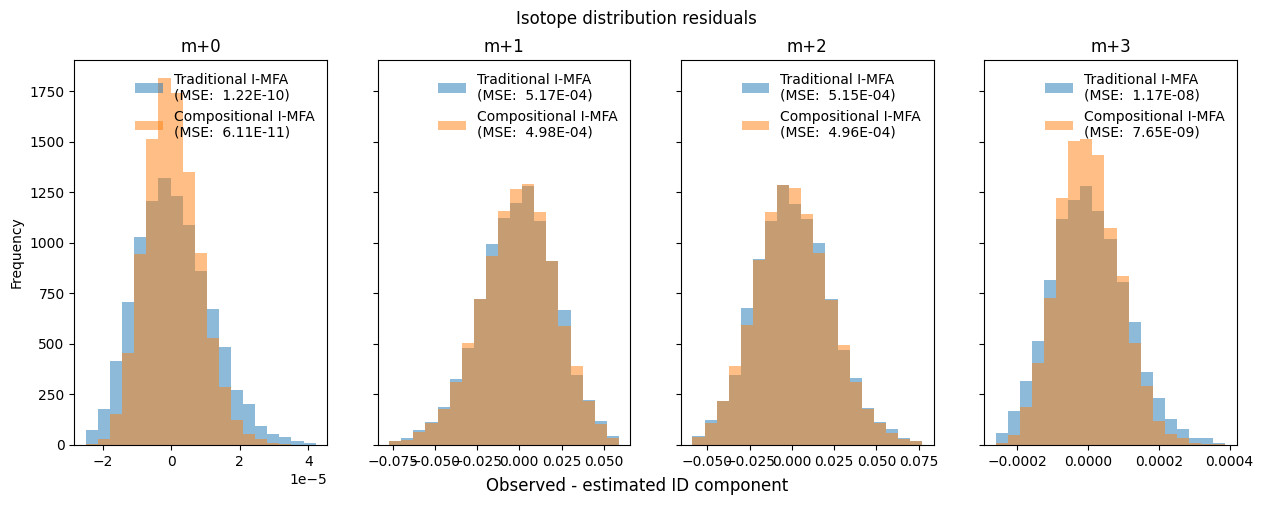

In [14]:
f, axes = plt.subplots(1, 4, figsize=[15, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_trad_i = id_resid_trad[:, i].flatten()
    resid_comp_i = id_resid_ilr[:, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 20)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {id_mse_trad[i]: .2E})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE: {id_mse_ilr[i]: .2E})" 
    )
    ax.set(title=f"m+{i}")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");
f.supxlabel("Observed - estimated ID component")

f.suptitle("Isotope distribution residuals");
f.savefig(PLOT_DIR / "id_residuals_toy_true.png", bbox_inches="tight", dpi=200)

In [15]:
with open(RESULTS_DIR / "estimated_fluxes_ci_reference.pkl", "rb") as f:
    estimated_fluxes_ci_reference = pickle.load(f)
estimated_fluxes_ci_reference["trad"].shape
flux_ci_trad = jnp.exp(jnp.log(estimated_fluxes_ci_reference["trad"][:,:,:]).mean(axis=0))
flux_ci_ilr = jnp.exp(jnp.log(estimated_fluxes_ci_reference["ilr"][:,:,:]).mean(axis=0))

In [16]:
flux = ["v2", "v4", "v6", "v1", "v3", "v5"]
print(f"{'Traditional':^42}")
print(f"{'Flux':<6} | {'Lower Bound':>15} | {'Upper Bound':>15}")
print("-" * 42)

for fl, (low, high) in zip(flux, flux_ci_trad):
    # :15.4f means 15 characters total width, 4 decimal places, as a float
    print(f"{fl:<6} | {low:15.4f} | {high:15.4f}")

               Traditional                
Flux   |     Lower Bound |     Upper Bound
------------------------------------------
v2     |          0.0147 |     839228.8812
v4     |          3.5753 |        111.4915
v6     |         14.3161 |        446.4333
v1     |        100.0000 |        100.0000
v3     |          0.0003 |    7408440.4747
v5     |          3.5753 |        111.4915


In [17]:
print(f"{'Compositional':^42}")
print(f"{'Flux':<6} | {'Lower Bound':>15} | {'Upper Bound':>15}")
print("-" * 42)

for fl, (low, high) in zip(flux, flux_ci_ilr):
    # :15.4f means 15 characters total width, 4 decimal places, as a float
    print(f"{fl:<6} | {low:15.4f} | {high:15.4f}")

              Compositional               
Flux   |     Lower Bound |     Upper Bound
------------------------------------------
v2     |         21.1999 |        578.4554
v4     |         13.7925 |         28.8847
v6     |         55.2474 |        115.7009
v1     |        100.0000 |        100.0000
v3     |         19.7208 |        129.4418
v5     |         13.7925 |         28.8847


# Sensitivity analysis

In [18]:
free_fluxes = jnp.load(RESULTS_DIR / "free_fluxes.npy")
free_fluxes.shape

(121, 2)

In [19]:
intensity_msts = jnp.load(RESULTS_DIR / "intensity_measurements.npy")
intensity_msts.shape

(121, 50, 4)

In [20]:
# id_msts_true = closure(intensity_msts[true_flux_index,:,:])

In [21]:
true_ids = jnp.load(RESULTS_DIR / "true_isotopologue_distributions.npy")

In [22]:
gini_indices= jnp.load(RESULTS_DIR / "gini_indices.npy")
entropies = jnp.load(RESULTS_DIR / "entropies.npy")

In [23]:
with open(RESULTS_DIR / "estimated_fluxes.pkl", "rb") as f:
    estimated_fluxes = pickle.load(f)
estimated_fluxes["trad"].shape

(121, 50, 6)

In [24]:
with open(RESULTS_DIR / "hessian_matrices.pkl", "rb") as f:
    hessian_matrices = pickle.load(f)
hessian_matrices["trad"].shape

(121, 50, 2, 2)

In [25]:
with open(RESULTS_DIR / "estimated_ids.pkl", "rb") as f:
    estimated_ids = pickle.load(f)
estimated_ids["trad"].shape

(121, 50, 4)

In [26]:
resid_trad = (free_fluxes[:, None, :] - estimated_fluxes["trad"][:, :, [4, 5]])
resid_clr = (free_fluxes[:, None, :] - estimated_fluxes["clr"][:, :, [4, 5]])
resid_ilr = (free_fluxes[:, None, :] - estimated_fluxes["ilr"][:, :, [4, 5]])

mse_trad = (resid_trad ** 2).mean(axis=(0, 1))
mse_clr = (resid_clr ** 2).mean(axis=(0, 1))
mse_ilr = (resid_ilr ** 2).mean(axis=(0, 1))

mse_trad, mse_clr, mse_ilr

(Array([235.61323964,   2.6185388 ], dtype=float64),
 Array([176.35574839,   2.58495348], dtype=float64),
 Array([176.35023834,   2.58811078], dtype=float64))

In [27]:
resid_trad.shape

(121, 50, 2)

In [28]:
id_resid_trad = (estimated_ids["trad"] - true_ids[:, None, :])
id_resid_clr = (estimated_ids["clr"] - true_ids[:, None, :])
id_resid_ilr = (estimated_ids["ilr"] - true_ids[:, None, :])

id_mse_trad = (id_resid_trad ** 2).mean(axis=(0, 1))
id_mse_clr = (id_resid_clr ** 2).mean(axis=(0, 1))
id_mse_ilr = (id_resid_ilr ** 2).mean(axis=(0, 1))

id_mse_trad, id_mse_clr, id_mse_ilr

(Array([6.95082694e-10, 5.10826195e-04, 5.08370111e-04, 2.87924643e-08],      dtype=float64),
 Array([3.83722062e-10, 4.93279443e-04, 4.90043244e-04, 1.95565725e-08],      dtype=float64),
 Array([3.82809616e-10, 4.93772132e-04, 4.90520258e-04, 1.95529085e-08],      dtype=float64))

In [29]:
true_ilrs = ordered_ilr_func(true_ids)
trad_ilrs = ordered_ilr_func(estimated_ids["trad"])
clr_ilrs = ordered_ilr_func(estimated_ids["clr"])
ilr_ilrs = ordered_ilr_func(estimated_ids["ilr"])

ilr_resid_trad = trad_ilrs - true_ilrs[:, None, :]
ilr_resid_clr = clr_ilrs - true_ilrs[:, None, :]
ilr_resid_ilr = ilr_ilrs - true_ilrs[:, None, :]

ilr_mse_trad = (ilr_resid_trad ** 2).mean(axis=(0, 1))
ilr_mse_clr = (ilr_resid_clr ** 2).mean(axis=(0, 1))
ilr_mse_ilr = (ilr_resid_ilr ** 2).mean(axis=(0, 1))

ilr_mse_trad, ilr_mse_clr, ilr_mse_ilr

(Array([8.04934261, 1.33631874, 3.93160207], dtype=float64),
 Array([0.00636707, 0.00964308, 0.00410909], dtype=float64),
 Array([0.00634162, 0.00965924, 0.00408897], dtype=float64))

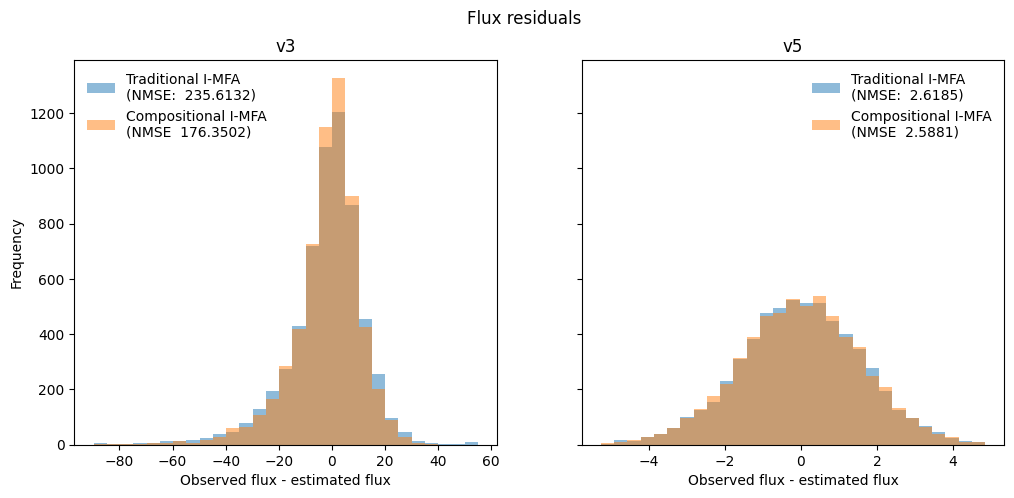

In [30]:
f, axes = plt.subplots(1, 2, figsize=[12, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_trad_i = resid_trad[:, :, i].flatten()
    resid_comp_i = resid_ilr[:, :, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(NMSE: {mse_trad[i]: .4f})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(NMSE {mse_ilr[i]: .4f})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{3+2*i}", xlabel="Observed flux - estimated flux")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");

f.suptitle("Flux residuals");
f.savefig(PLOT_DIR / "flux_residuals_toy.png", bbox_inches="tight", dpi=200)

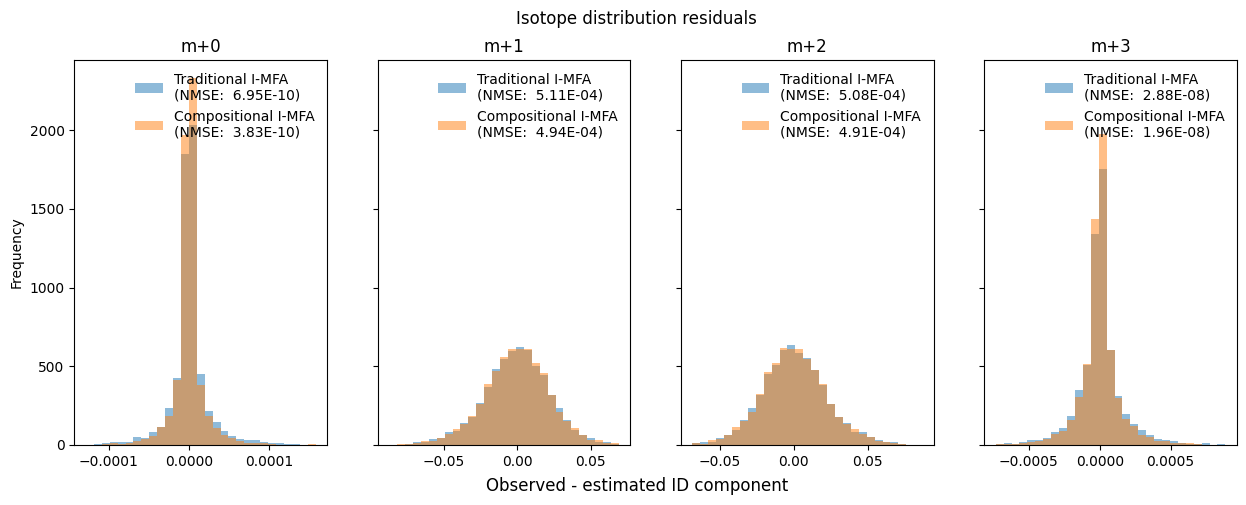

In [31]:
f, axes = plt.subplots(1, 4, figsize=[15, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_trad_i = id_resid_trad[:, :, i].flatten()
    resid_comp_i = id_resid_ilr[:, :, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(NMSE: {id_mse_trad[i]: .2E})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(NMSE: {id_mse_ilr[i]: .2E})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"m+{i}")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");
f.supxlabel("Observed - estimated ID component")

f.suptitle("Isotope distribution residuals");
f.savefig(PLOT_DIR / "id_residuals_toy.png", bbox_inches="tight", dpi=200)

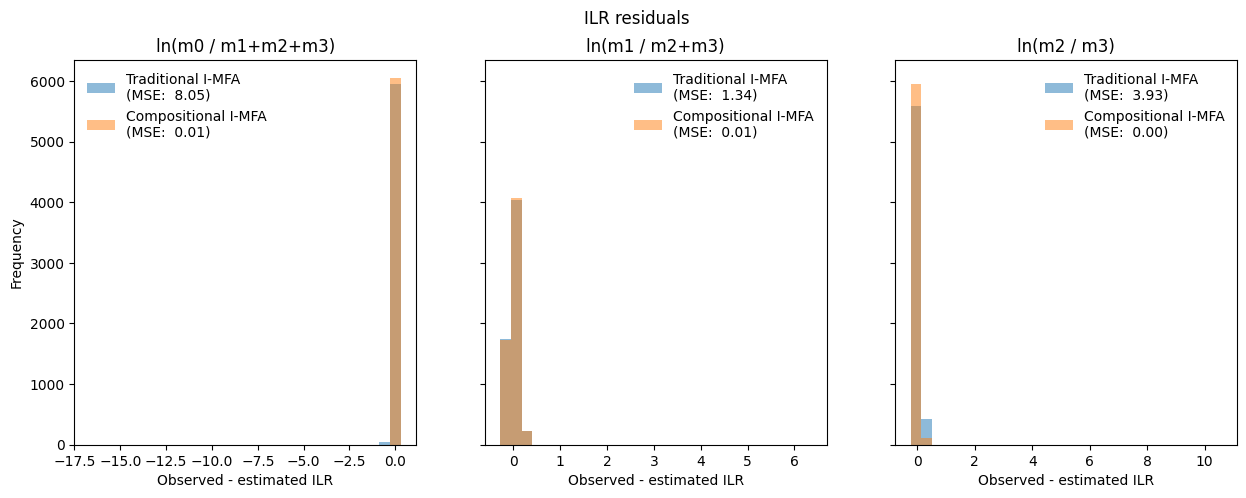

In [32]:
ratio_lhs = (f"m{i}" for i in range(3))
ratio_rhs = ("+".join([f"m{j}" for j in range(i+1, 4)]) for i in range(3))
labels = (f"ln({ratio_lhs_i} / {ratio_rhs_i})" for ratio_lhs_i, ratio_rhs_i in zip(ratio_lhs, ratio_rhs))


f, axes = plt.subplots(1, 3, figsize=[15, 5], sharey=True)

for (i, ax), label in zip(enumerate(axes), labels):
    resid_trad_i = ilr_resid_trad[:, :, i].flatten()
    resid_comp_i = ilr_resid_ilr[:, :, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.00185)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.998)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {ilr_mse_trad[i]: .2f})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE: {ilr_mse_ilr[i]: .2f})" 
    )
    ax.set(title=label, xlabel="Observed - estimated ILR")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");
f.suptitle("ILR residuals");

**Figure caption** Traditional vs Compositional I-MFA flux estimates on a toy model. We fit traditional and compositional I-MFA to 1000 simulated datasets based on the toy model in [Antoniewicz reference]. The datasets were simulated assuming noise on pre-closure measurements with constant coefficient of variation based on a model of mass spectrometer intensity measurements (lognormal scale parameter 0.1, corresponding to approximately 2% worst error after closure to compositions).

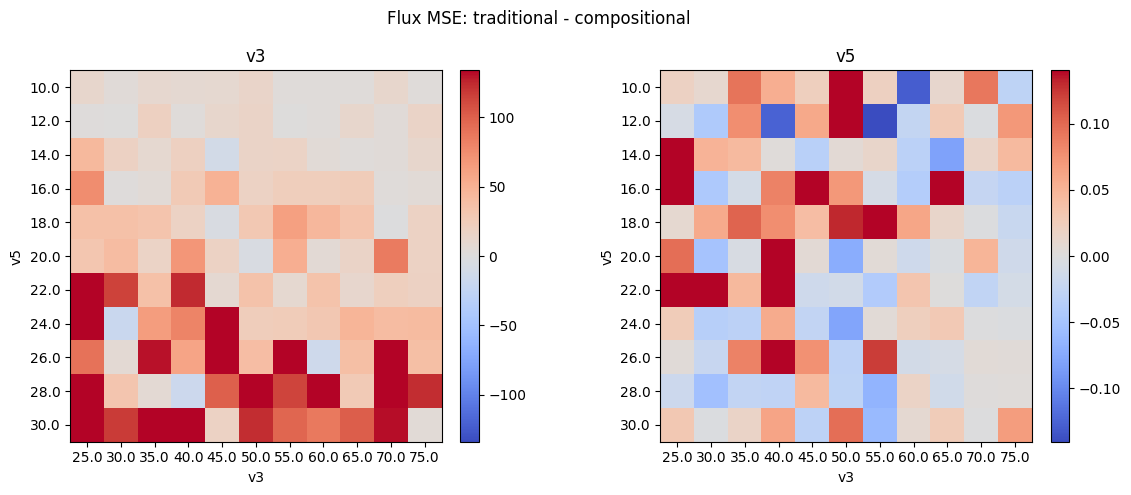

In [33]:
f, axes = plt.subplots(1, 2, figsize=[12, 5])
axes = axes.ravel()

xs = np.unique(free_fluxes[:, 0])
ys = np.unique(free_fluxes[:, 1])

diff = (resid_trad ** 2).mean(axis=1) - (resid_ilr ** 2).mean(axis=1)

for i in range(2):
    halfrange = np.quantile(np.abs(diff[:, i]), 0.9)
    norm = CenteredNorm(vcenter=0, halfrange=halfrange)
    im = axes[i].imshow(diff[:, i].reshape([11, 11]), cmap="coolwarm", norm=norm)
    f.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)
    axes[i].set_xticks(np.arange(len(xs)), xs)
    axes[i].set_yticks(np.arange(len(ys)), ys)
    axes[i].set(xlabel="v3", ylabel="v5", title=f"v{3+2*i}")
f.suptitle("Flux MSE: traditional - compositional")

f.tight_layout()

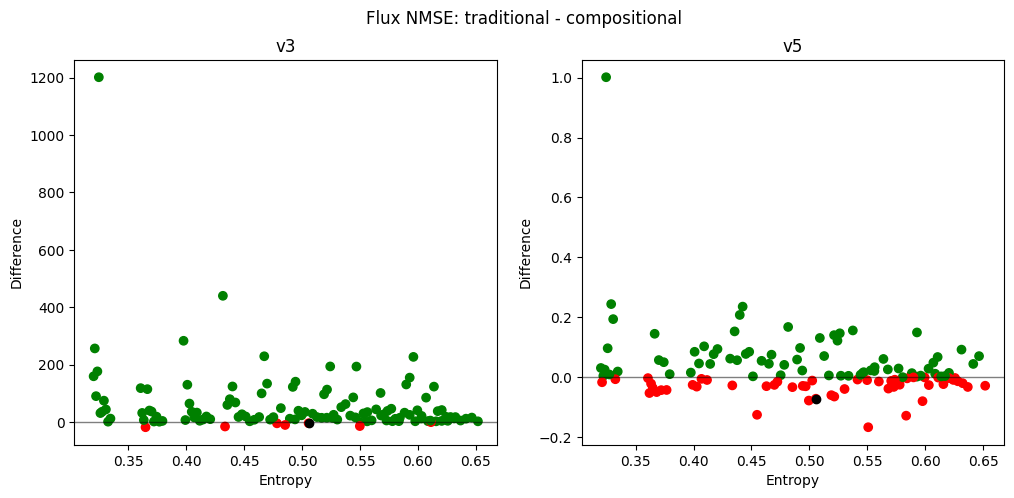

In [34]:
diff_flux = ((resid_trad ** 2).mean(axis=1) - (resid_ilr ** 2).mean(axis=1))

f, axes = plt.subplots(1, 2, figsize=[12, 5])
axes = axes.ravel()
true_flux_index = 60
for i in range(2):
    y_values = diff_flux[:, i]
    colors = np.where(y_values >= 0, 'green', 'red')
    axes[i].scatter(entropies, y_values, c=colors)
    axes[i].scatter(entropies[true_flux_index], y_values[true_flux_index], color="black", label="Reference flux")
    axes[i].axhline(0, color='black', lw=1, alpha=0.5)
    axes[i].set(xlabel="Entropy", ylabel="Difference", title=f"v{3+2*i}")
f.suptitle("Flux NMSE: traditional - compositional")
plt.show()


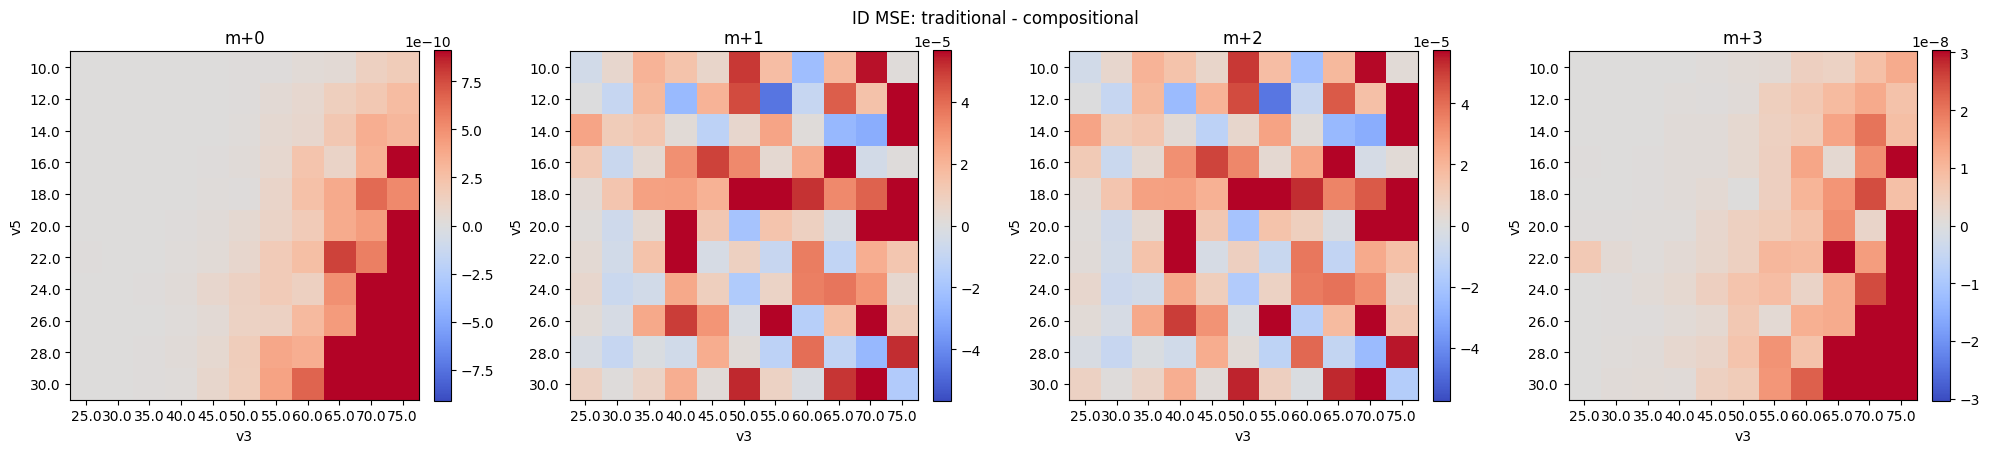

In [35]:
f, axes = plt.subplots(1, 4, figsize=[20, 8])
axes = axes.ravel()

xs = np.unique(free_fluxes[:, 0])
ys = np.unique(free_fluxes[:, 1])

diff_id = (id_resid_trad ** 2).mean(axis=1) - (id_resid_ilr ** 2).mean(axis=1)

for i in range(4):
    halfrange = np.quantile(np.abs(diff_id[:, i]), 0.9)
    norm = CenteredNorm(vcenter=0, halfrange=halfrange)
    im = axes[i].imshow(diff_id[:, i].reshape([11, 11]), cmap="coolwarm", norm=norm)
    f.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)
    axes[i].set_xticks(np.arange(len(xs)), xs)
    axes[i].set_yticks(np.arange(len(ys)), ys)
    axes[i].set(xlabel="v3", ylabel="v5", title=f"m+{i}")
f.suptitle("ID MSE: traditional - compositional", y=0.75);
f.tight_layout()

In [36]:
diff_id = ((id_resid_trad ** 2).mean(axis=1) - (id_resid_ilr ** 2).mean(axis=1))
# /((id_resid_trad ** 2).mean(axis=1))
gini_id = jnp.column_stack((gini_indices, diff_id))

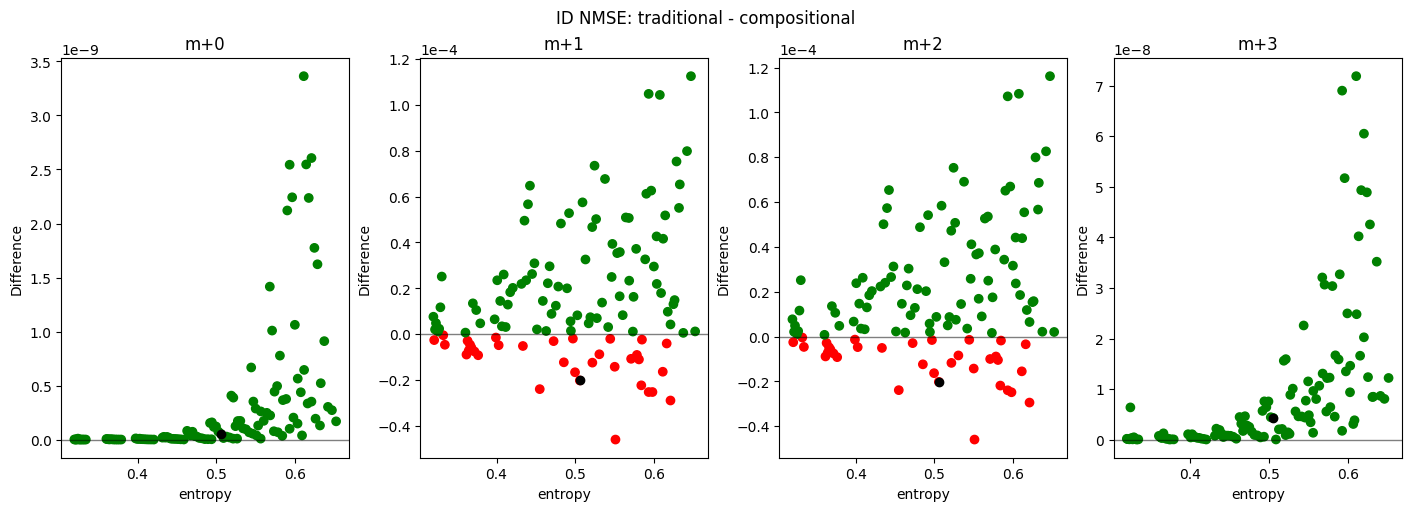

In [37]:
f, axes = plt.subplots(1, 4, figsize=[14, 5], layout="constrained")
axes = axes.ravel()

for (i, axes) in enumerate(axes):
    y_values = diff_id[:, i]
    colors = np.where(y_values >= 0, 'green', 'red')
    axes.scatter(entropies, y_values, c=colors)
    axes.scatter(entropies[true_flux_index], y_values[true_flux_index], color="black", label="Reference flux")
    axes.axhline(0, color='black', lw=1, alpha=0.5)
    axes.set(xlabel="entropy", ylabel="Difference", title=f"m+{i}")
    axes.ticklabel_format(scilimits=(-2,3))
f.suptitle("ID NMSE: traditional - compositional")
plt.show()

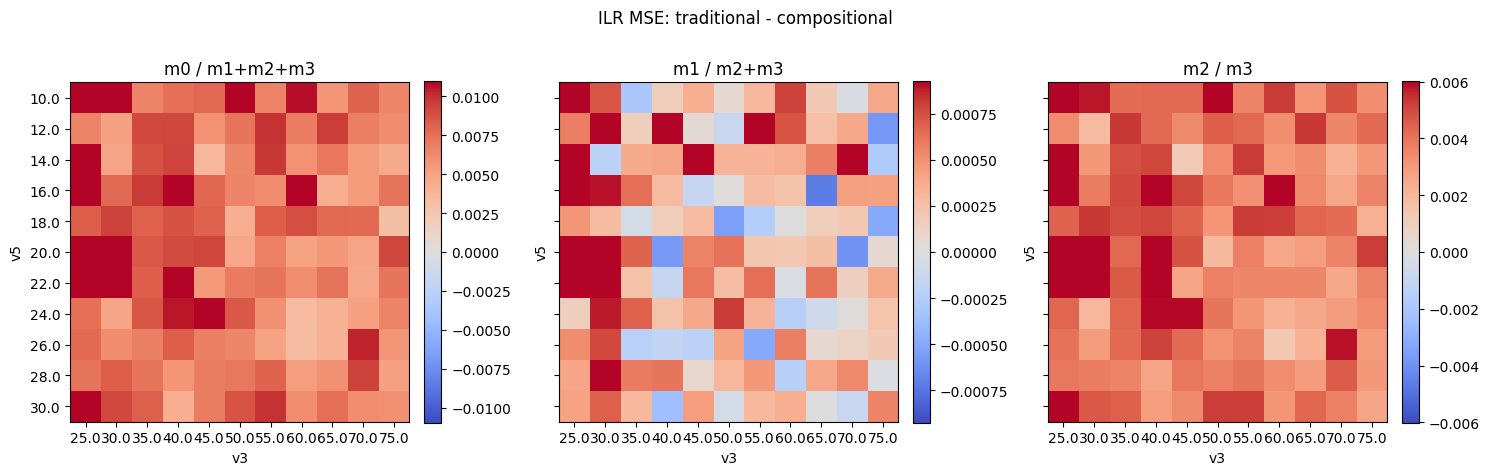

In [38]:
f, axes = plt.subplots(1, 3, sharey=True, figsize=[15, 5])

xs = np.unique(free_fluxes[:, 0])
ys = np.unique(free_fluxes[:, 1])

diff = (ilr_resid_trad ** 2).mean(axis=1) - (ilr_resid_ilr ** 2).mean(axis=1)

ratio_lhs = (f"m{i}" for i in range(3))
ratio_rhs = ("+".join([f"m{j}" for j in range(i+1, 4)]) for i in range(3))
labels = (f"{ratio_lhs_i} / {ratio_rhs_i}" for ratio_lhs_i, ratio_rhs_i in zip(ratio_lhs, ratio_rhs))


for i, label in enumerate(labels):
    halfrange = np.quantile(np.abs(diff[:, i]), 0.9)
    norm = CenteredNorm(vcenter=0, halfrange=halfrange)
    im = axes[i].imshow(diff[:, i].reshape([11, 11]), cmap="coolwarm", norm=norm)
    f.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)
    axes[i].set_xticks(np.arange(len(xs)), xs)
    axes[i].set_yticks(np.arange(len(ys)), ys)
    axes[i].set(xlabel="v3", ylabel="v5", title=label)
f.suptitle("ILR MSE: traditional - compositional", y=0.96);
f.tight_layout()

**Figure caption** Traditional vs Compositional I-MFA isotopologue estimates on a toy model. Note that compositional I-MFA is far better than traditional I-MFA at estimating ratios that are sensitive to the low-abundance isotopologues m0 and m3.

# Confidence intervals with MC

In [39]:
flux_ci_trad = jnp.exp(jnp.log(estimated_fluxes_ci_reference["trad"][:,:,:]).mean(axis=0))
flux_ci_ilr = jnp.exp(jnp.log(estimated_fluxes_ci_reference["ilr"][:,:,:]).mean(axis=0))

v3_trad = estimated_fluxes_ci_reference["trad"][:,4,:]
v5_trad = estimated_fluxes_ci_reference["trad"][:,5,:]

v3_ilr = estimated_fluxes_ci_reference["ilr"][:,4,:]
v5_ilr = estimated_fluxes_ci_reference["ilr"][:,5,:]

In [40]:
print(np.quantile(v3_ilr[:,0],0.05))
print(np.quantile(v3_ilr[:,0],0.95))


15.976199914272579
24.252522799422902


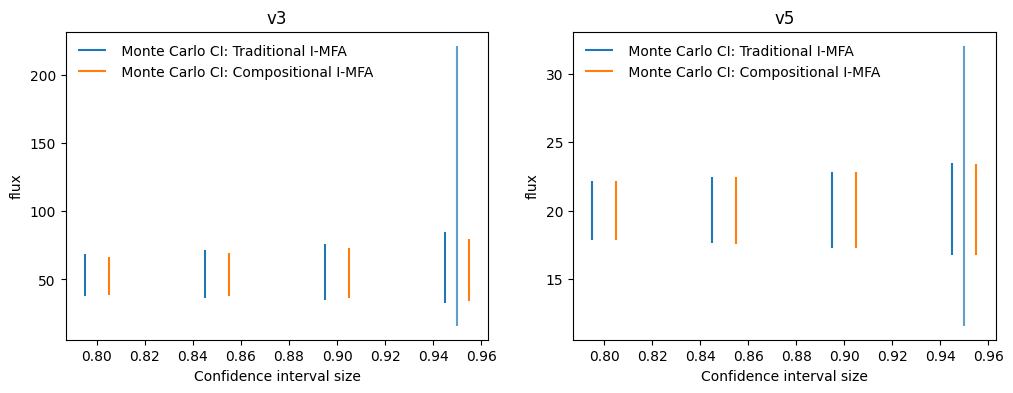

In [41]:
def get_ci_bounds(ci_size):
    low = (1.0 - ci_size) / 2
    high = 1.0 - low
    return low, high

IX_FREE_FLUXES = np.array([4,5])

with open(RESULTS_DIR / "estimated_fluxes_reference.pkl", "rb") as f:
    mc_estimated_fluxes = pickle.load(f)

mc_free_fluxes = {k: v[:, IX_FREE_FLUXES] for k, v in mc_estimated_fluxes.items()}
mc_free_fluxes["trad"].shape

N_BOUND = 4

plot_df_rows = []
ci_sizes = np.linspace(0.80, 0.95, N_BOUND)
for i, ci_size in enumerate(ci_sizes):
    row = {"ci_size": ci_size}
    qlow, qhigh = get_ci_bounds(ci_size)
    for model in ("trad", "ilr"):
        row[f"{model}_low_4"] = np.quantile(mc_estimated_fluxes[model][:, 4], qlow, axis=0)
        row[f"{model}_low_5"] = np.quantile(mc_estimated_fluxes[model][:, 5], qlow, axis=0)
        row[f"{model}_high_4"] = np.quantile(mc_estimated_fluxes[model][:, 4], qhigh, axis=0)
        row[f"{model}_high_5"] = np.quantile(mc_estimated_fluxes[model][:, 5], qhigh, axis=0)
    plot_df_rows.append(row)


plot_df = pl.DataFrame(plot_df_rows)
f, axes = plt.subplots(1, 2, figsize=[12, 4])
axes = axes.ravel()
for ax, flux_ix in zip(axes, (4, 5)):
    for offset, model, color in zip((-0.005, 0.005), ("trad", "ilr"), ("tab:blue", "tab:orange")):
        ax.vlines(
            plot_df["ci_size"] + offset, 
            plot_df[f"{model}_low_{flux_ix}"], 
            plot_df[f"{model}_high_{flux_ix}"], 
            color=color,
            label=" Monte Carlo CI: " + model.replace("ilr", "Compositional I-MFA").replace("trad", "Traditional I-MFA")
        )
    # ax.axhline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]: .2f})")
    ax.set(xlabel="Confidence interval size", ylabel="flux", title=f"v{(flux_ix-4)*2 + 3}")
    ax.legend(frameon=False, loc="upper left")

x_pos = np.full((10000, 1), 0.95)
axes[0].vlines(x=0.95,  ymin=np.quantile(v3_ilr[:,0],0.05), ymax = np.quantile(v3_ilr[:,1],0.95), alpha=0.7)
axes[1].vlines(x=0.95,  ymin=np.quantile(v5_ilr[:,0],0.05), ymax = np.quantile(v5_ilr[:,1],0.95), alpha=0.7)
plt.show()
# x_pos = np.full((10000, 1), 0.96)
# axes[0].vlines(x=x_pos,  ymin=v3_trad[:,0], ymax = v3_trad[:,1], alpha=0.1)
# axes[1].vlines(x=x_pos,  ymin=v5_trad[:,0], ymax = v5_trad[:,1], alpha=0.1)

In [42]:
flux_ci_trad

Array([[1.46577510e-02, 8.39228881e+05],
       [3.57527695e+00, 1.11491540e+02],
       [1.43160866e+01, 4.46433262e+02],
       [1.00000000e+02, 1.00000000e+02],
       [3.45281486e-04, 7.40844047e+06],
       [3.57527695e+00, 1.11491540e+02]], dtype=float64)

In [43]:
flux_ci_ilr

Array([[ 21.19988792, 578.45542272],
       [ 13.79252879,  28.88474021],
       [ 55.24744802, 115.70091368],
       [100.        , 100.        ],
       [ 19.72084999, 129.44182679],
       [ 13.79252879,  28.88474021]], dtype=float64)

In [44]:
simulated_id[287,:]

Array([5.97921550e-05, 8.11858660e-01, 1.87202523e-01, 8.79024955e-04],      dtype=float64)

In [45]:
import numpy as np
import jax.numpy as jnp
from functools import partial
import pypesto
import optimistix
from pypesto.result import OptimizerResult
import pypesto.profile as profile
import sys

# Ensure your custom module is findable
sys.path.insert(0, "../scripts")
import toy_network

# 1. Setup Data
sd = np.array([8.31665129e-06, 2.27196635e-02, 2.26783995e-02, 1.18495971e-04])
sim_id = simulated_id[1]
weights = 1/sd

# 2. Optimization with Optimistix
# Note: Ensure loss_trad signature is: loss_trad(params, args)
init_guess = jnp.array([100.0, 50.0])
solver = optimistix.BFGS(rtol=1e-8, atol=1e-8)

opt_result = optimistix.minimise(
    toy_network.loss_trad,
    y0=jnp.log(init_guess),
    args=(sim_id, weights),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

# 3. Create pyPESTO Objective
# PyPESTO will call this function as objective(x)
def my_loss_function(x): 
    return toy_network.loss_trad(x, args=(sim_id, weights))[0] 

objective = pypesto.Objective(fun=my_loss_function)

# 4. Define Problem
problem = pypesto.Problem(
    objective=objective,
    lb=[-10] * 2, 
    ub=[8] * 2,  
    x_names=['v3', 'v5']
)

# 5. Manually inject the Optimistix result into pyPESTO
result_trad = pypesto.Result(problem=problem)
opt_result_manual = OptimizerResult(
    x=np.array(opt_result.value),        # Convert JAX to NumPy
    fval=float(opt_result.state.f_info.f),          # Cast JAX scalar to float
    id="optimistix_bfgs",
)
result_trad.optimize_result.append(opt_result_manual)

# 6. Profile Likelihood
# pyPESTO will now use Scipy to "walk" the likelihood surface
result_trad = profile.parameter_profile(
    problem=problem,
    result=result_trad,
    optimizer=pypesto.optimize.ScipyOptimizer(),
    filename=None
)

print(result_trad)

100%|██████████| 4/4 [01:05<00:00, 16.32s/it]

In [1]:
s1 = 123
s2 = 255
s3 = 919

In [46]:
sim_id = simulated_id[s1]
sim_ids = np.array([simulated_id[s1],simulated_id[s2],simulated_id[s3]])
sd = np.std(sim_ids, axis=0)
sd_all = np.std(simulated_id)
weights = 1/sd_all

In [47]:
def wssr(y, args):
    target, weights = args
    return jnp.sum(weights * (y - target) ** 2)

In [98]:
def wssr_two(y, args):
    target, weights = args
    if target.ndim>1:   
        n_dim = target.shape[0]
        ys = jnp.tile(y, (n_dim, 1))
    else:
        ys=y
    return jnp.sum(weights * (ys - target) ** 2)

In [109]:
wssr(simulated_id[100], args=(sim_id, weights))

Array(0.00129079, dtype=float64)

In [112]:
wssr_two(simulated_id[100], args=(sim_ids, weights))

Array(0.00815309, dtype=float64)

In [101]:
target=simulated_id[100]
ys = sim_id
jnp.sum(weights * (ys - target) ** 2)

Array(0.00129079, dtype=float64)

In [104]:
target_two=sim_ids
n_dim = target_two.shape[0]
print(n_dim)


3


In [105]:
ys_two = jnp.tile(sim_id, (n_dim,1))
jnp.sum(weights * (ys_two - target_two) ** 2)

Array(0.00632828, dtype=float64)

In [106]:
ys_two-target_two

Array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00],
       [ 5.81280787e-06,  1.63986388e-02, -1.61366372e-02,
        -2.67814437e-04],
       [ 1.28975931e-05, -2.78540712e-02,  2.77598453e-02,
         8.13283053e-05]], dtype=float64)

In [107]:
sim_id

Array([7.57856421e-05, 7.86354910e-01, 2.12722869e-01, 8.46435795e-04],      dtype=float64)